# Titanic SHAP + AI Workshop

Run **Setup** top to bottom, then go play in **Your Turn**.

Three things are yours to edit: which passenger you explain, the glossary describing what the features mean, and the prompt itself.

## Setup

In [1]:
import textwrap
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.ensemble import GradientBoostingClassifier
import shap
import matplotlib.pyplot as plt
import ollama

In [2]:
# Load and prep Titanic data
df = sns.load_dataset("titanic")

features = ["pclass", "age", "sibsp", "parch", "fare", "sex", "embarked"]
df = df[features + ["survived"]].dropna()

# Encode categoricals
df["sex"] = df["sex"].map({"male": 0, "female": 1})
df["embarked"] = df["embarked"].map({"S": 0, "C": 1, "Q": 2})

X = df[features]
y = df["survived"]

print(f"Dataset shape: {X.shape}")
display(X.head())

print("\nTarget (y) - 'survived':")
display(y.head())
print(y.value_counts())

Dataset shape: (712, 7)


,pclass,age,sibsp,parch,fare,sex,embarked
0,3,22.0,1,0,7.2500,0,0
1,1,38.0,1,0,71.2833,1,1
2,3,26.0,0,0,7.9250,1,0
3,1,35.0,1,0,53.1000,1,0
4,3,35.0,0,0,8.0500,0,0



Target (y) - 'survived':


0    0
1    1
2    1
3    1
4    0
Name: survived, dtype: int64

survived
0    424
1    288
Name: count, dtype: int64


In [3]:
gb_model = GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42)
gb_model.fit(X, y)

train_acc = gb_model.score(X, y)
print(f"Training accuracy: {train_acc:.3f}")

Training accuracy: 0.910


In [4]:
explainer = shap.TreeExplainer(gb_model)
shap_values = explainer(X)

print(f"SHAP values shape: {shap_values.values.shape}")

SHAP values shape: (712, 7)


In [5]:
VALUE_LABELS = {
    "sex": {0: "male", 1: "female"},
    "embarked": {0: "Southampton", 1: "Cherbourg", 2: "Queenstown"},
}


def decode_value(feature, val):
    mapping = VALUE_LABELS.get(feature)
    if mapping is not None:
        return mapping.get(val, val)
    if isinstance(val, float) and val.is_integer():
        return int(val)
    return val


MODEL = "llama3.1"


def plot_waterfall(idx):
    """Display SHAP waterfall plot with actual/predicted outcome in the title."""
    sv = shap_values[idx]
    survival_prob = gb_model.predict_proba(X.iloc[[idx]])[0][1]
    predicted = "survived" if survival_prob >= 0.5 else "did not survive"
    actual = "survived" if y.iloc[idx] else "did not survive"

    sv_disp = shap.Explanation(
        values=sv.values,
        base_values=sv.base_values,
        data=sv.data,
        display_data=np.array(
            [str(decode_value(name, val)) for name, val in zip(sv.feature_names, sv.data)]
        ),
        feature_names=sv.feature_names,
    )
    shap.plots.waterfall(sv_disp, show=False)
    plt.title(
        f"Passenger {idx}  |  Actual: {actual}  |  Predicted: {predicted} ({survival_prob:.1%})",
        fontsize=10,
    )
    plt.tight_layout()
    plt.show()


def describe_value(feature, val):
    """The FEATURE_CONTEXT note for one specific value, or "" if there isn't one."""
    entry = FEATURE_CONTEXT.get(feature)
    if entry is None:
        return ""
    if "values" in entry:
        return entry["values"].get(int(val), "")
    for upper, text in entry.get("bands", []):
        if val < upper:
            return text
    return ""


def context_block(idx, top_n=4):
    """Glossary notes for the features that drove this prediction.

    Reads whatever FEATURE_CONTEXT currently holds, so editing that cell and re-running
    changes the explanation. Features missing from the glossary are skipped.
    """
    sv = shap_values[idx]
    ranked = sorted(
        zip(sv.feature_names, sv.data, sv.values),
        key=lambda t: abs(t[2]),
        reverse=True,
    )

    lines = []
    for name, val, _ in ranked[:top_n]:
        entry = FEATURE_CONTEXT.get(name)
        if entry is None:
            continue
        lines.append(f"  {name}: {entry['description']}")
        note = describe_value(name, val)
        if note:
            lines.append(f"    {decode_value(name, val)} means: {note}")
    return "\n".join(lines) or "  (no glossary entries for this passenger's top features)"


def explain_passenger(idx):
    """Stream a plain-English SHAP explanation for passenger at row idx, using the
    current PROMPT_TEMPLATE and FEATURE_CONTEXT from the 'Your Turn' section below."""
    sv = shap_values[idx]
    survival_prob = gb_model.predict_proba(X.iloc[[idx]])[0][1]
    predicted = "survived" if survival_prob >= 0.5 else "did not survive"
    actual = "survived" if y.iloc[idx] else "did not survive"

    shap_lines = "\n".join(
        f"  {name:12s}  value={decode_value(name, val):<8}  shap={contrib:+.4f}"
        for name, val, contrib in sorted(
            zip(sv.feature_names, sv.data, sv.values),
            key=lambda t: abs(t[2]),
            reverse=True,
        )
    )

    prompt = PROMPT_TEMPLATE.format(
        passenger=dict(X.iloc[idx]),
        actual=actual,
        predicted=predicted,
        prob=survival_prob,
        shap_lines=shap_lines,
        context=context_block(idx),
    )

    response = ollama.chat(
        model=MODEL,
        messages=[{"role": "user", "content": prompt}],
        keep_alive="10m",
    ).message.content
    print(textwrap.fill(response, width=80))


def explain_with_plot(idx):
    """Show the waterfall plot then stream the LLM explanation for passenger at row idx."""
    plot_waterfall(idx)
    explain_passenger(idx)

## Your Turn

Three knobs. The glossary and the prompt are defined in the next two cells, and the last cell picks a passenger and runs everything.

1. **`FEATURE_CONTEXT`** the glossary. SHAP tells you *how much* a feature mattered, not what it means, so this is where the domain knowledge lives.
2. **`PROMPT_TEMPLATE`** the instructions. `{context}` is where the glossary gets injected, so you can move it, reframe it, or delete it to see the explanation without it.
3. **`passenger_idx`** which passenger gets explained, 0 to 711.

Edit either of the first two, re-run that cell, then re-run the last cell to see the effect.

In [7]:
# <-- edit these descriptions, add features, or delete entries, then re-run
# Categorical features use "values", numeric ones use "bands" of (upper_bound, note).
FEATURE_CONTEXT = {
    "sex": {
        "description": "Recorded sex. The evacuation followed 'women and children first'.",
        "values": {
            0: "Male. Men were loaded only after women and children, and many were turned away.",
            1: "Female. Prioritised at the lifeboats.",
        },
    },
    "pclass": {
        "description": "Ticket class. Stands in for wealth and for location on the ship.",
        "values": {
            1: "First class. Upper deck cabins, nearest the lifeboats.",
            2: "Second class. Mid ship, a moderate distance from the lifeboats.",
            3: "Third class. Lower decks, the longest route to the boat deck.",
        },
    },
    "age": {
        "description": "Age in years. Children were prioritised alongside women.",
        "bands": [
            (12, "A child, prioritised at the lifeboats."),
            (50, "A working age adult, with no priority beyond sex and class."),
            (200, "An older adult, who had more trouble reaching the boat deck quickly."),
        ],
    },
    "fare": {
        "description": "Ticket price in 1912 pounds. Tracks class closely.",
        "bands": [
            (10, "A cheap third class fare."),
            (30, "A typical third or low second class fare."),
            (80, "A comfortable second or lower first class fare."),
            (10000, "An expensive first class fare, implying a well placed cabin."),
        ],
    },
    "sibsp": {
        "description": (
            "Siblings and spouses aboard. Counts family only, so someone travelling with "
            "a servant or a friend looks the same as someone travelling alone."
        ),
        "bands": [
            (1, "No siblings or spouse aboard, though possibly with companions this cannot see."),
            (2, "One sibling or a spouse aboard, the group size with the best odds."),
            (20, "A large family, which struggled to stay together during the evacuation."),
        ],
    },
    "parch": {
        "description": "Parents and children aboard. Same family-only blind spot as sibsp.",
        "bands": [
            (1, "No parents or children aboard."),
            (20, "Travelling with parents or children."),
        ],
    },
    "embarked": {
        "description": (
            "Port of boarding. The port saved nobody. It correlates with class and "
            "nationality, so the model treats it as a weak proxy for those."
        ),
        "values": {
            0: "Southampton, the main departure port. Only 19 percent first class.",
            1: "Cherbourg, France. Skewed wealthy at 57 percent first class.",
            2: "Queenstown, Ireland. Almost entirely third class, and only 28 passengers here.",
        },
    },
}

# To preview what the prompt will receive, call context_block(idx) with any row number.

  sex: Recorded sex. The evacuation followed 'women and children first'.
    female means: Female. Prioritised at the lifeboats.
  pclass: Ticket class. Stands in for wealth and for location on the ship.
    1 means: First class. Upper deck cabins, nearest the lifeboats.
  fare: Ticket price in 1912 pounds. Tracks class closely.
    71.2833 means: A comfortable second or lower first class fare.
  embarked: Port of boarding. The port saved nobody. It correlates with class and nationality, so the model treats it as a weak proxy for those.
    Cherbourg means: Cherbourg, France. Skewed wealthy at 57 percent first class.


In [10]:
PROMPT_TEMPLATE = """
You are explaining a prediction to someone with no technical background. Use no unnecessary language and use plain everyday language - no jargon.

Passenger: {passenger}
Actual outcome: {actual}
Predicted outcome: {predicted} ({prob:.1%} probability)

Feature contributions (positive = pushed toward survived, negative = pushed toward did not survive):
{shap_lines}

What these features mean. This is background from the historical record, not something the model knows:
{context}

In 2-3 sentences, explain who this passenger was, what was predicted to happen and what did. Also explain which characteristics contributed most to surviving or not
"""
# <-- try editing the instructions above, then re-run this cell and the last one


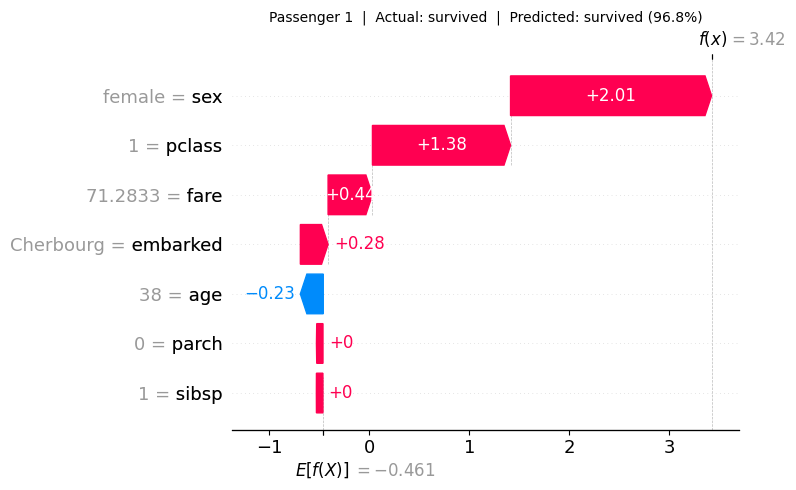

This passenger was a 38-year-old woman, traveling in first class and paying a
fare that was considered comfortable for the time. The model predicted that she
would survive with a 96.8% probability, and that's exactly what happened. The
features that contributed most to her survival were being a woman (pushed toward
survival by +2.0078), traveling in first class (+1.3794), and having a high fare
(+0.4429).


In [ ]:
# run here
passenger_idx = 1  # <-- try changing this (0-711)
explain_with_plot(passenger_idx)

## Extra Time: Batch a Few Passengers

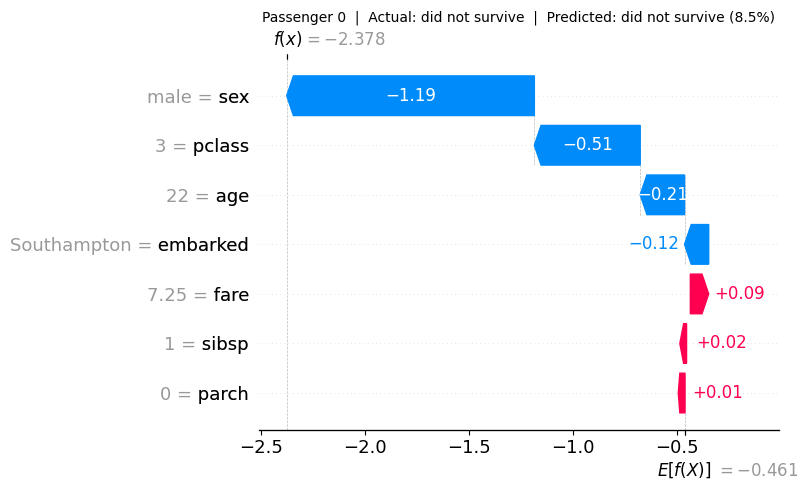

This passenger was a 22-year-old man who was traveling in third class on the
ship. The model predicted that he wouldn't survive with an 8.5% chance of being
wrong. Unfortunately, the actual outcome was that he did not survive.  The
features that contributed most to his predicted outcome were his sex (being
male) and ticket class (third class), which both pushed him towards not
surviving. His age and port of boarding also contributed to this prediction, but
to a lesser extent. The only feature that slightly counteracted this was his
fare, which was relatively low, but it wasn't enough to change the overall
outcome.




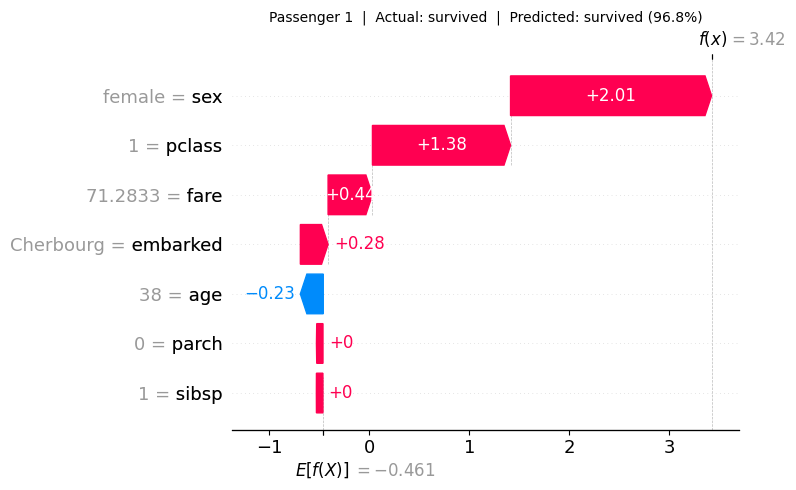

This passenger was a 38-year-old female, traveling in first class, and her
ticket price was around 71 pounds. We predicted that she would survive with a
96.8% probability, and that's what actually happened. The characteristics that
contributed most to her surviving were being female, traveling in first class,
and having a relatively high ticket price, which all likely gave her a higher
priority in getting on a lifeboat.




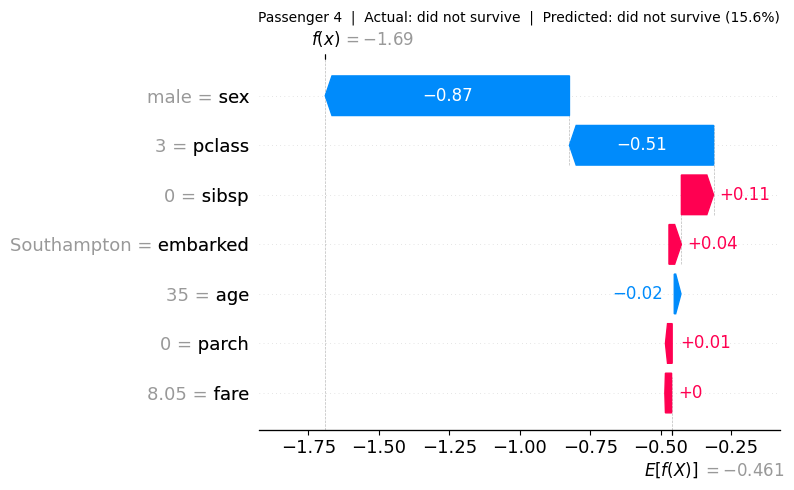

This passenger was a 35-year-old man who traveled in third class from
Southampton. The model predicted that he would not survive with a 15.6%
probability, and that's what actually happened.  The characteristics that
contributed most to him not surviving were his sex (being male) and ticket class
(being in third class). The model suggests that being a man and traveling in a
lower-class ticket made it more likely for him to not survive, possibly because
men were loaded last and many were turned away.




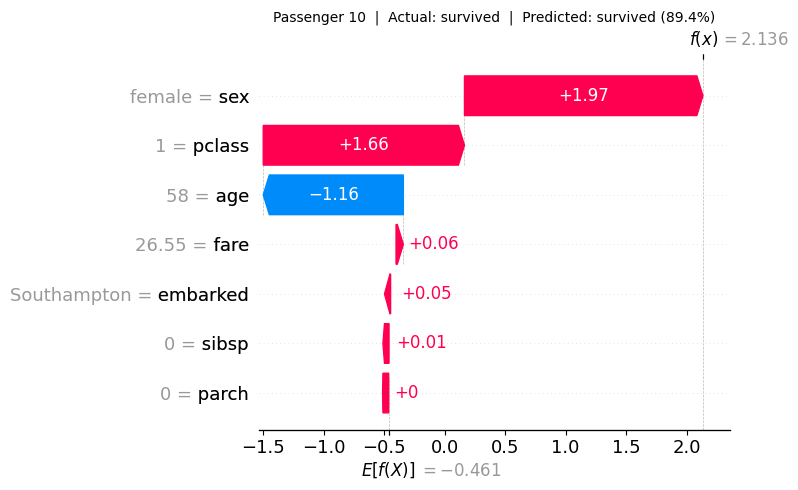

Here's a plain explanation:  This passenger was a 58-year-old woman who traveled
in first class, which was near the lifeboats. The model predicted she would
survive, and that's exactly what happened. The features that most contributed to
her survival were being female and traveling in first class, which gave her a
higher priority on the lifeboats.




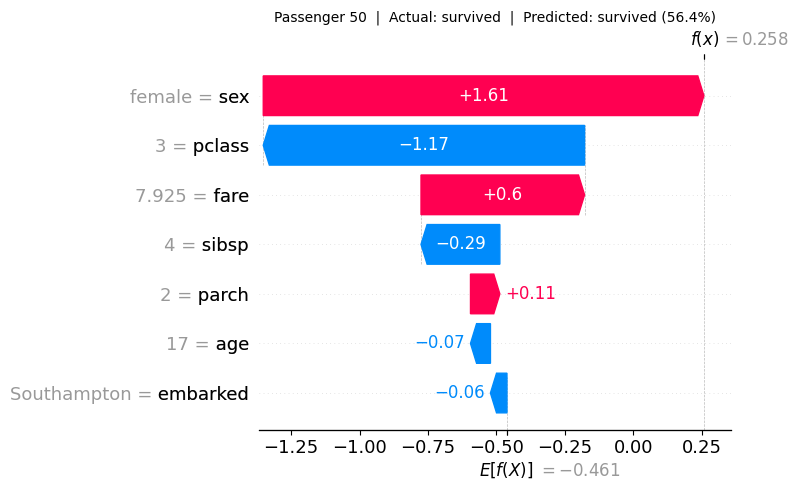

This passenger was a 17-year-old girl from a large family, traveling in third
class, which was the lowest class on the ship. The model predicted she would
survive, and indeed, she did. The characteristics that contributed most to her
survival were being female, which was a priority in the evacuation, and having a
relatively low ticket price, indicating she was from a lower-income family.




In [9]:
for idx in [0, 1, 4, 10, 50]:
    explain_with_plot(idx)
    print("\n" + "=" * 60 + "\n")